Dataset:


,StudyHours,Attendance,Result
0,1.0,55,Fail
1,1.5,60,Fail
2,2.0,62,Fail
3,2.5,65,Fail
4,3.0,68,Fail
5,3.5,70,Pass
6,4.0,75,Pass
7,4.5,78,Pass
8,5.0,82,Pass
9,5.5,85,Pass


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Actual and Predicted Results:
Actual: Fail Predicted: Fail
Actual: Pass Predicted: Pass
Actual: Pass Predicted: Pass


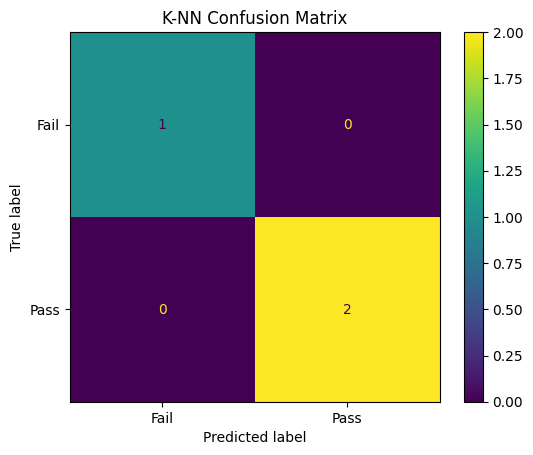

              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

data = pd.DataFrame({
    "StudyHours": [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5],
    "Attendance": [55, 60, 62, 65, 68, 70, 75, 78, 82, 85, 88, 92],
    "Result": ["Fail", "Fail", "Fail", "Fail", "Fail", "Pass",
               "Pass", "Pass", "Pass", "Pass", "Pass", "Pass"]
})

print("Dataset:")
display(data)

X = data[["StudyHours", "Attendance"]]
y = data["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="Pass", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, pos_label="Pass", zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, pos_label="Pass", zero_division=0))

print("\nActual and Predicted Results:")
for actual, predicted in zip(y_test, y_pred):
    print("Actual:", actual, "Predicted:", predicted)

cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail", "Pass"]).plot()
plt.title("K-NN Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, zero_division=0))